In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
def append_csv(source_file, target_file):
    source_data = pd.read_csv(source_file, skiprows = 0)
    target_data = pd.read_csv(target_file, skiprows = 1)

    combined_data = pd.concat([source_data, target_data])
    combined_data.to_csv(target_file, index=False)

# Example usage
source_file = 'RL_mimo_ofdm/PPO_2ue16Nt_buffer/monitor_12.csv'
target_file = 'RL_mimo_ofdm/PPO_2ue16Nt_buffer/monitor_13.csv'
# append_csv(source_file, target_file)

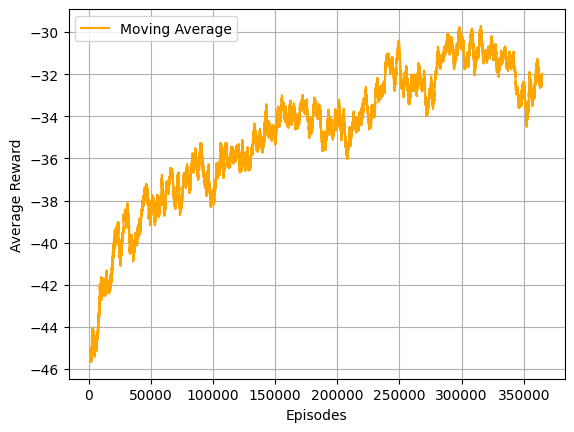

In [3]:


monitor_file = "RL_mimo_ofdm/PPO_2ue16Nt_buffer/monitor_13.csv"
# MONITOR_2 is temporary file for testing. It is still running
monitor_data = pd.read_csv(monitor_file, skiprows=0)

window_size = 2000
moving_average = monitor_data['r'].rolling(window=window_size).mean()

fig, ax = plt.subplots()
ax.plot(moving_average, label='Moving Average', color='orange')
ax.legend()
ax.grid()
ax.set_xlabel('Episodes')
ax.set_ylabel('Average Reward')

plt.show()

I changed the calculation of latency. In order to do so, I slightly changed the buffer, which becomes a stack to capture the waiting time. 
The model is trained for around 50 hours.

The entropy loss of the policy goes from -22.5 to -2.68. 


**Benchmark**
The BS estimates the AoDs using MUSIC algorithm based on the reflected echoes. 
Then, the BS best beams to users according to these estimated AoDs.

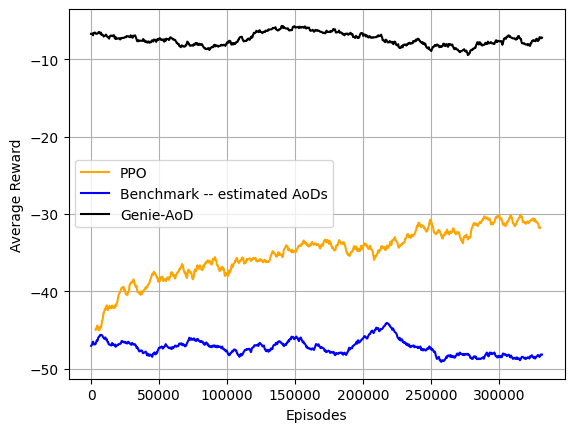

In [4]:
import numpy as np
monitor_file = "RL_mimo_ofdm/PPO_2ue16Nt_buffer/monitor_12.csv"
# MONITOR_95 is temporary file for testing. It is still running
monitor_data = pd.read_csv(monitor_file, skiprows=0)

window_size = 3000
moving_average = monitor_data['r'].rolling(window=window_size).mean()

benchmark_reward = pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_buffer/benchmark/reward.csv', skiprows=0)
br = benchmark_reward['Reward'].rolling(window = 100).mean()
br_length = len(br.dropna())
selected_values = moving_average[::len(moving_average)//br_length][:(br_length)]

genie_reward = pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_buffer/genie/reward.csv', skiprows=0)
gr = genie_reward['Reward'].rolling(window = 100).mean()

fig, ax = plt.subplots()
ax.plot( selected_values, label='PPO', color='orange')

ax.plot(np.linspace(0, len(moving_average), br_length), br.dropna(), label='Benchmark -- estimated AoDs', color='blue')
ax.plot(np.linspace(0, len(moving_average), br_length), gr.dropna(), label='Genie-AoD', color='black')

ax.legend()
ax.grid()
ax.set_xlabel('Episodes')
ax.set_ylabel('Average Reward')

plt.show()

In [19]:
print(len(moving_average)//br_length)
length_of_br = len(br)
print(length_of_br)

290
1000


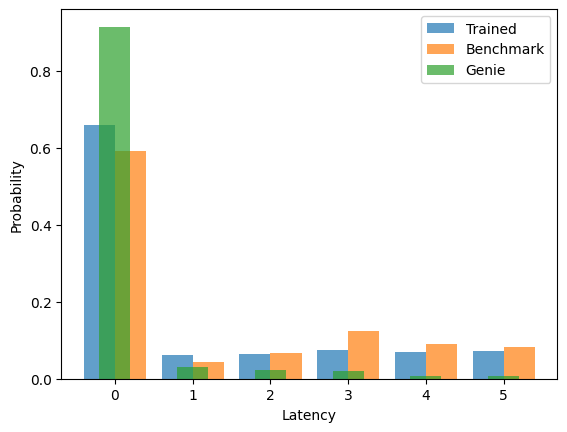

In [49]:
import matplotlib.pyplot as plt
import itertools

fd1 = 'RL_mimo_ofdm/PPO_2ue16Nt_buffer/trained/'
fd2 = 'RL_mimo_ofdm/PPO_2ue16Nt_buffer/benchmark/'
latency_t = pd.read_csv(fd1 + 'latency.csv', skiprows=0)
latency_b = pd.read_csv(fd2 + 'latency.csv', skiprows=0)

latency_g = pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_buffer/genie/latency.csv', skiprows=0)

latency_benchmark = list(itertools.chain(*latency_t.values))
latency_trained = list(itertools.chain(*latency_b.values))
latency_genie = list(itertools.chain(*latency_g.values))
figure_handle = plt.figure()
ax2 = figure_handle.add_subplot()

counts_trained, bins_trained, patches_trained = ax2.hist(latency_trained, bins=range(7), density=True, alpha=0.7, label='Trained')
counts_benchmark, bins_benchmark, patches_benchmark = ax2.hist(latency_benchmark, bins=range(7), density=True, alpha=0.7, label='Benchmark')
counts_genie, bins_genie, patches_genie = ax2.hist(latency_genie, bins=range(7), density=True, alpha=0.7, label='Genie')

bin_centers = 0.5 * (bins_trained[:-1] + bins_trained[1:])

ax2.cla()  # Clear the previous plot
ax2.bar(bin_centers - 0.2, counts_trained, width=0.4, align='center', alpha=0.7, label='Trained')
ax2.bar(bin_centers + 0.2, counts_benchmark, width=0.4, align='center', alpha=0.7, label='Benchmark')
ax2.bar(bin_centers, counts_genie, width=0.4, align='center', alpha=0.7, label='Genie')

ax2.set_xticks(bin_centers)
ax2.set_xticklabels(range(6))
ax2.set_xlabel('Latency')
ax2.set_ylabel('Probability')
ax2.legend()

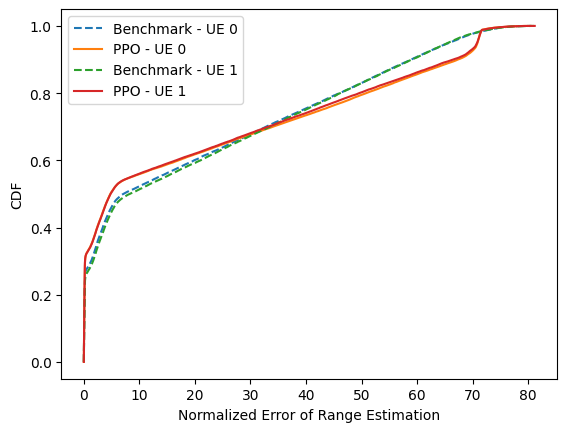

(39999, 2)
(39999, 2)


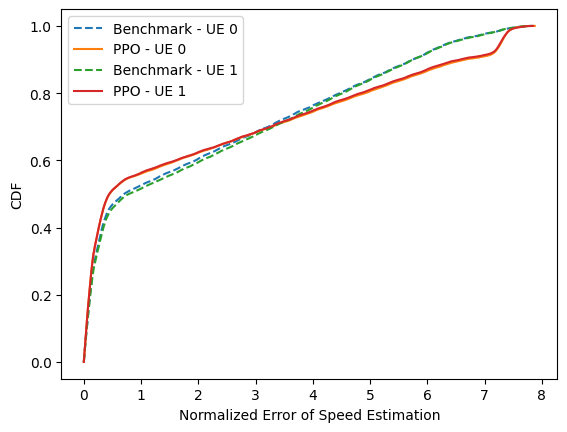

In [51]:
#### CDF of estimation error ####
er_t = pd.read_csv(fd1 + 'nmseR_allsteps.csv', skiprows=1)
er_b = pd.read_csv(fd2 + 'nmseR_allsteps.csv', skiprows=1)

ev_t = pd.read_csv(fd1 + 'nmseV_allsteps.csv', skiprows=1)
ev_b = pd.read_csv(fd2 + 'nmseV_allsteps.csv', skiprows=1)

figure_handle = plt.figure()
ax3 = figure_handle.add_subplot()
er_benchmark = np.array(er_b)
er_trained = np.array(er_t)
ev_benchmark = np.array(ev_b)
ev_trained = np.array(ev_t)

for u in range(2):
    
    temp = er_benchmark[:,u]
    er_cdf = np.sort(temp)
    yvals = np.arange(len(er_cdf))/float(len(er_cdf)-1)
    ax3.plot(er_cdf, yvals, '--', label='Benchmark - UE %d'%u)

    temp = er_trained[:,u]
    er_cdf = np.sort(temp)
    yvals = np.arange(len(er_cdf))/float(len(er_cdf)-1)
    ax3.plot(er_cdf, yvals, '-', label='PPO - UE %d'%u)

ax3.set_xlabel('Normalized Error of Range Estimation')
ax3.set_ylabel('CDF')
ax3.legend()
plt.show()

print(er_benchmark.shape)
print(er_trained.shape)
figure_handle = plt.figure()
ax4 = figure_handle.add_subplot()
for u in range(2):
    temp = ev_benchmark[:,u]
    ev_cdf = np.sort(temp)
    yvals = np.arange(len(ev_cdf))/float(len(ev_cdf)-1)
    ax4.plot(ev_cdf, yvals, '--', label='Benchmark - UE %d'%u)

    temp = ev_trained[:,u]
    ev_cdf = np.sort(temp)
    yvals = np.arange(len(ev_cdf))/float(len(ev_cdf)-1)
    ax4.plot(ev_cdf, yvals, '-', label='PPO - UE %d'%u)
ax4.set_xlabel('Normalized Error of Speed Estimation')
ax4.set_ylabel('CDF')
ax4.legend()
plt.show()


In [30]:
print(np.shape(er_benchmark))

(40000, 2)


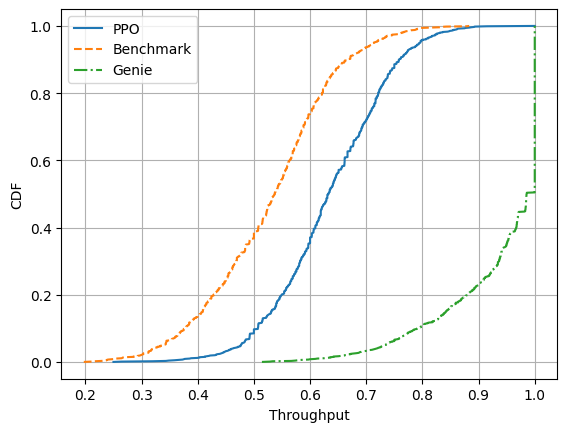

In [50]:
#### Throughput CDF ####
throughput_t = pd.read_csv(fd1 + 'throughput.csv', skiprows=0)
throughput_b = pd.read_csv(fd2 + 'throughput.csv', skiprows=0)
throughput_g = pd.read_csv('RL_mimo_ofdm/PPO_2ue16Nt_buffer/genie/throughput.csv', skiprows=0)

figure_handle = plt.figure()
ax = figure_handle.add_subplot()

thp_cdf = np.sort(throughput_t['Throughput'])
yvals = np.arange(len(thp_cdf))/float(len(thp_cdf)-1)
ax.plot(thp_cdf, yvals, '-', label='PPO')

thp_cdf = np.sort(throughput_b['Throughput'])
yvals = np.arange(len(thp_cdf))/float(len(thp_cdf)-1)
ax.plot(thp_cdf, yvals, '--', label='Benchmark')

thp_cdf = np.sort(throughput_g['Throughput'])
yvals = np.arange(len(thp_cdf))/float(len(thp_cdf)-1)
ax.plot(thp_cdf, yvals, '-.', label='Genie')
ax.legend()
ax.set_xlabel('Throughput')
ax.set_ylabel('CDF')
ax.grid()